# Model Development and Training

## Dataset Exploration and Train/Test/Val Splitting

The proteins have a pairwise similarity $\le 25\%$. This means that we should have diversity in sequence composition and evolutionary relationships, so that no two chains are close homologs and each chain can be treated as an independent sample.

In [1]:
import torch
import torch.nn.functional as F
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

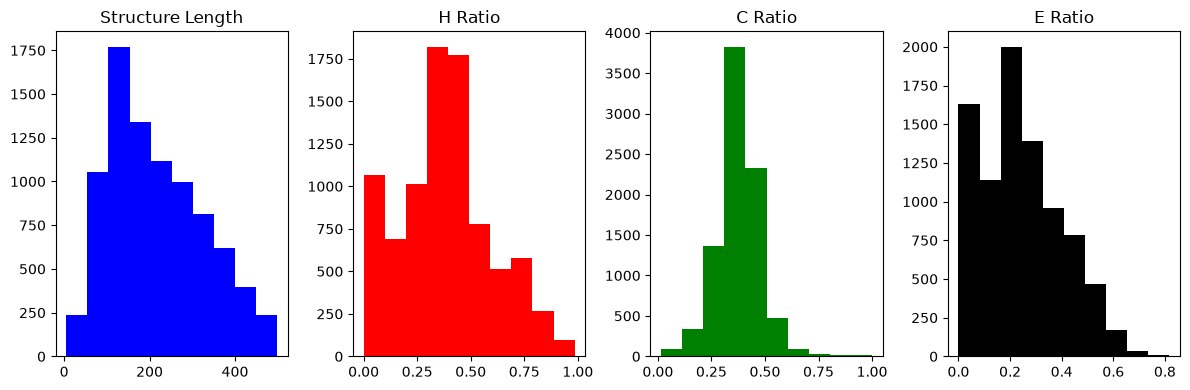

In [2]:
df = pd.read_csv("./selected_proteins.csv")

df["seq_length"] = df["structure"].str.len()
df["H_ratio"] = df["structure"].str.count("H") / df["seq_length"]
df["C_ratio"] = df["structure"].str.count("C") / df["seq_length"]
df["E_ratio"] = df["structure"].str.count("E") / df["seq_length"]

fig, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, figsize=(12, 4))

ax1.hist(df["seq_length"], color="blue")
ax1.set_title("Structure Length")

ax2.hist(df["H_ratio"], color = "red")
ax2.set_title("H Ratio")

ax3.hist(df["C_ratio"], color = "green")
ax3.set_title("C Ratio")

ax4.hist(df["E_ratio"], color = "black")
ax4.set_title("E Ratio")

plt.tight_layout()
plt.show()

We see that the ratios of label class distributions of H, C, and E are not equal. When splitting the data for training, testing, and validation the distributions of the same class should be similar. Additionally, when validating the models we do this by label class and not over all classes.

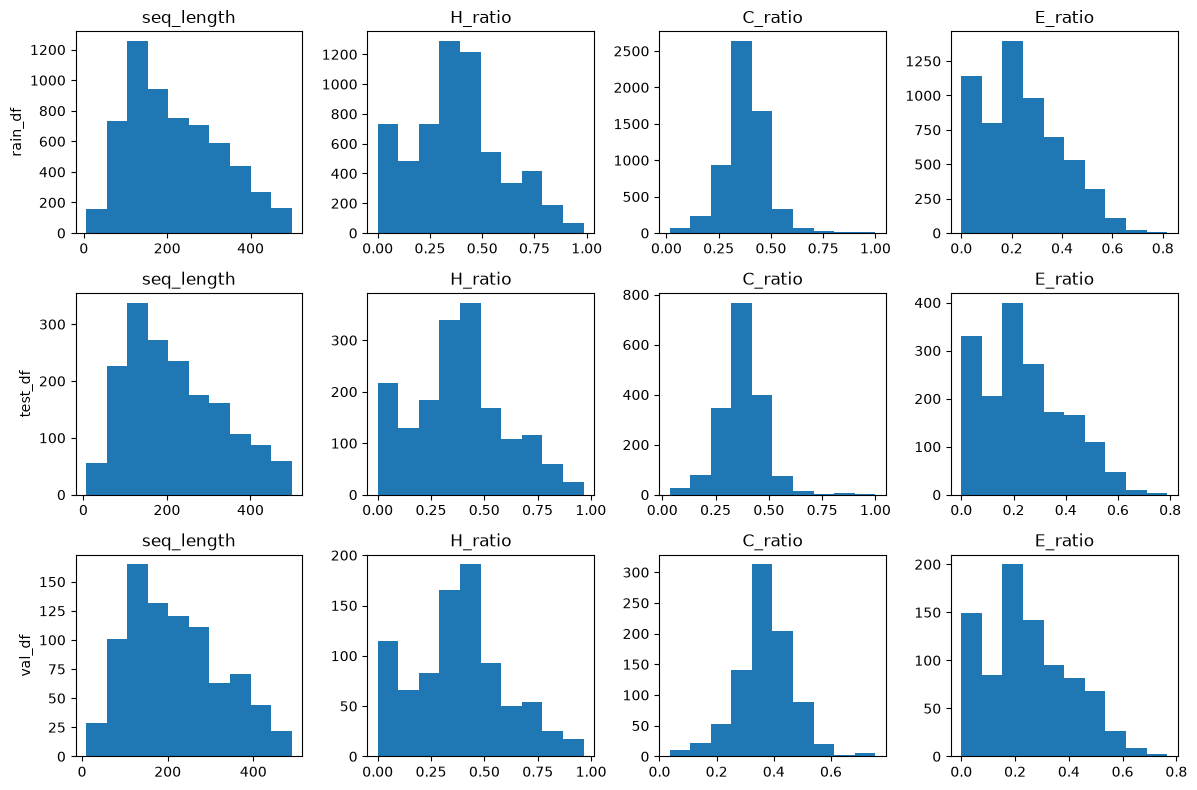

In [3]:
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import GroupShuffleSplit

df["chain_key"] = df["pdb_id"] + "_" + df["chain"].astype(str)

groups = df["chain_key"]

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(df, groups=groups))
train_df, test_df = df.iloc[train_idx], df.iloc[test_idx]

gss_val = GroupShuffleSplit(n_splits=1, test_size=0.125, random_state=42)
tr_idx, val_idx = next(gss_val.split(train_df, groups=train_df["chain_key"]))
val_df = train_df.iloc[val_idx]
train_df = train_df.iloc[tr_idx]

fig, axs = plt.subplots(3, 4, figsize=(12, 8))

row_titles = ["rain_df", "test_df", "val_df"]
for i, df in enumerate([train_df, test_df, val_df]):
    axs[i, 0].set_ylabel(row_titles[i])
    for j, col in enumerate(["seq_length", "H_ratio", "C_ratio", "E_ratio"]):
        axs[i, j].hist(df[col])
        axs[i, j].set_title(col)

plt.tight_layout()
plt.show()


By randomly splitting the large dataset we see that the distributions are very similar within label classes. We do not need to use stratified splitting in this case as proportions are visually identical.

In [4]:
AA = "ACDEFGHIKLMNPQRSTVWYX" 
aa_to_idx = {a: i for i, a in enumerate(AA)}
X_IDX = aa_to_idx["X"]

def encode_seq(seq):
    idx = torch.tensor([aa_to_idx.get(a, X_IDX) for a in seq.upper()],
                       dtype=torch.long)
    return F.one_hot(idx, num_classes=len(AA)).float()


ss_to_idx = {"H": 0, "E": 1, "C": 2}
def encode_labels(s):
    return torch.tensor([ss_to_idx[c] for c in s], dtype=torch.long)

def windows(onehot, half=7):
    padded = F.pad(onehot, (0, 0, half, half))        # pad along the length dimension
    w = padded.unfold(0, 2 * half + 1, 1)             # (L, 21, 15)
    return w.permute(0, 2, 1).reshape(len(onehot), -1)  # (L, 15*21)

def build(split_df):
    X = torch.cat([windows(encode_seq(s)) for s in split_df["sequence"]])
    y = torch.cat([encode_labels(s) for s in split_df["structure"]])
    return TensorDataset(X, y)

train_dataset, val_dataset, test_dataset = build(train_df), build(val_df), build(test_df)

train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)
print(len(train_dataset), len(val_dataset), len(test_dataset))

1305365 186500 372048


## Softmax Classification Training and Evaluation

For an initial test case, I want to evaluate whether the Softmax classification would be able to handle this task.

epoch   1 | train loss 0.8759 | val loss 0.8712 | val Q3 0.6055
epoch   2 | train loss 0.8718 | val loss 0.8707 | val Q3 0.6055
epoch   3 | train loss 0.8711 | val loss 0.8709 | val Q3 0.6055
epoch   4 | train loss 0.8707 | val loss 0.8692 | val Q3 0.6034
epoch   5 | train loss 0.8704 | val loss 0.8694 | val Q3 0.6046
epoch   6 | train loss 0.8705 | val loss 0.8678 | val Q3 0.6014
epoch   7 | train loss 0.8703 | val loss 0.8703 | val Q3 0.5996
epoch   8 | train loss 0.8701 | val loss 0.8680 | val Q3 0.6050
epoch   9 | train loss 0.8700 | val loss 0.8670 | val Q3 0.6048
epoch  10 | train loss 0.8699 | val loss 0.8683 | val Q3 0.6013
epoch  11 | train loss 0.8700 | val loss 0.8689 | val Q3 0.5975
epoch  12 | train loss 0.8699 | val loss 0.8684 | val Q3 0.6014
epoch  13 | train loss 0.8699 | val loss 0.8703 | val Q3 0.6049
epoch  14 | train loss 0.8697 | val loss 0.8691 | val Q3 0.5975
early stopping at epoch 14


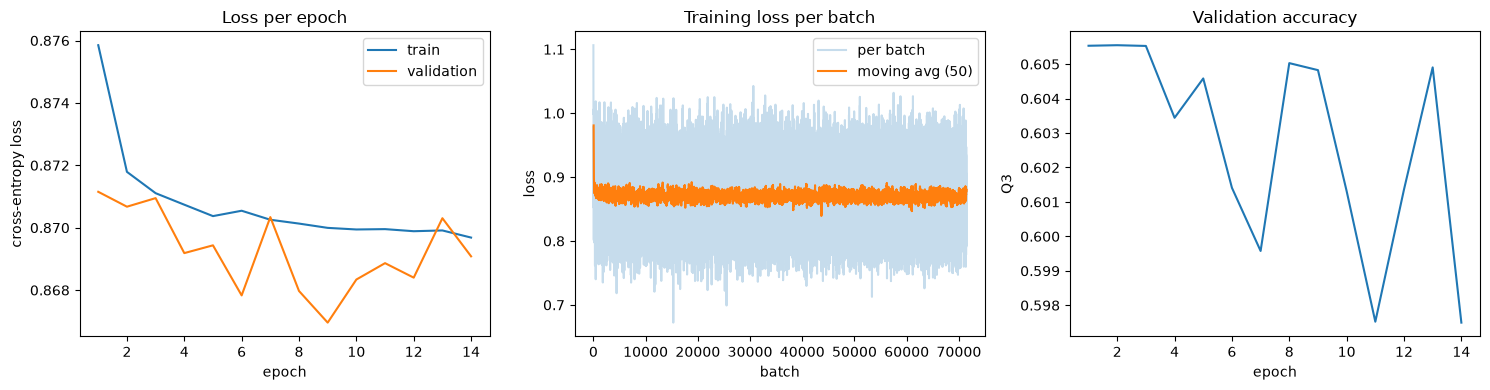

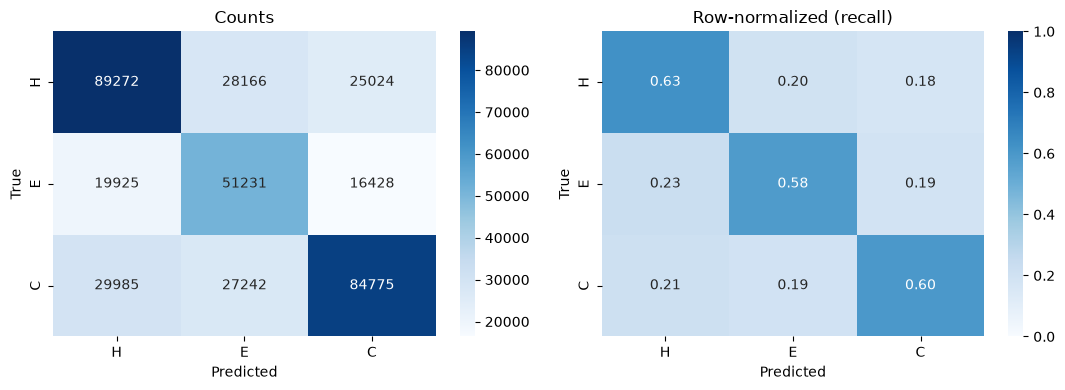

Q3 accuracy: 0.6055
class  precision    recall        f1   support
H          0.641     0.627     0.634    142462
E          0.480     0.585     0.528     87584
C          0.672     0.597     0.632    142002

Confusion matrix (rows = true, cols = predicted):
             H       E       C
H        89272   28166   25024
E        19925   51231   16428
C        29985   27242   84775


(0.6055079102516174,
 tensor([0.6414, 0.4804, 0.6716]),
 tensor([0.6266, 0.5849, 0.5970]))

In [5]:
import torch, torch.nn as nn
from softmax_ss import SoftmaxRegression, train, plot_history, evaluate, report

counts = torch.bincount(train_dataset.tensors[1]).float()
class_weight = counts.sum() / (len(counts) * counts)

model = SoftmaxRegression(n_features=315)
history = train(model, train_loader, val_loader, epochs=20, lr=1e-2, class_weight=class_weight)
plot_history(history)

_, pred, true = evaluate(model, test_loader, nn.CrossEntropyLoss())
report(pred, true)

## 1D-CNN + Softmax Classifier Training and Evaluation

Because adjacent residues effect nearby positions a Convolutional Neural Network (CNN) is a good model choice as a window of 15 residues are fed into the model. The output unnormalized logits are then an input to the softmax classifier for a per residue class prediction.

epoch   1 | train loss 0.9038 | val loss 0.8393 | val Q3 0.6294
epoch   2 | train loss 0.8138 | val loss 0.7750 | val Q3 0.6532
epoch   3 | train loss 0.7872 | val loss 0.7635 | val Q3 0.6654
epoch   4 | train loss 0.7757 | val loss 0.7565 | val Q3 0.6659
epoch   5 | train loss 0.7700 | val loss 0.7534 | val Q3 0.6759
epoch   6 | train loss 0.7625 | val loss 0.7573 | val Q3 0.6750
epoch   7 | train loss 0.7607 | val loss 0.7462 | val Q3 0.6687
epoch   8 | train loss 0.7556 | val loss 0.7405 | val Q3 0.6764
epoch   9 | train loss 0.7523 | val loss 0.7402 | val Q3 0.6798
epoch  10 | train loss 0.7506 | val loss 0.7360 | val Q3 0.6739
epoch  11 | train loss 0.7476 | val loss 0.7354 | val Q3 0.6764
epoch  12 | train loss 0.7486 | val loss 0.7381 | val Q3 0.6667
epoch  13 | train loss 0.7463 | val loss 0.7372 | val Q3 0.6830
epoch  14 | train loss 0.7461 | val loss 0.7324 | val Q3 0.6816
epoch  15 | train loss 0.7448 | val loss 0.7312 | val Q3 0.6815
epoch  16 | train loss 0.7421 | val loss

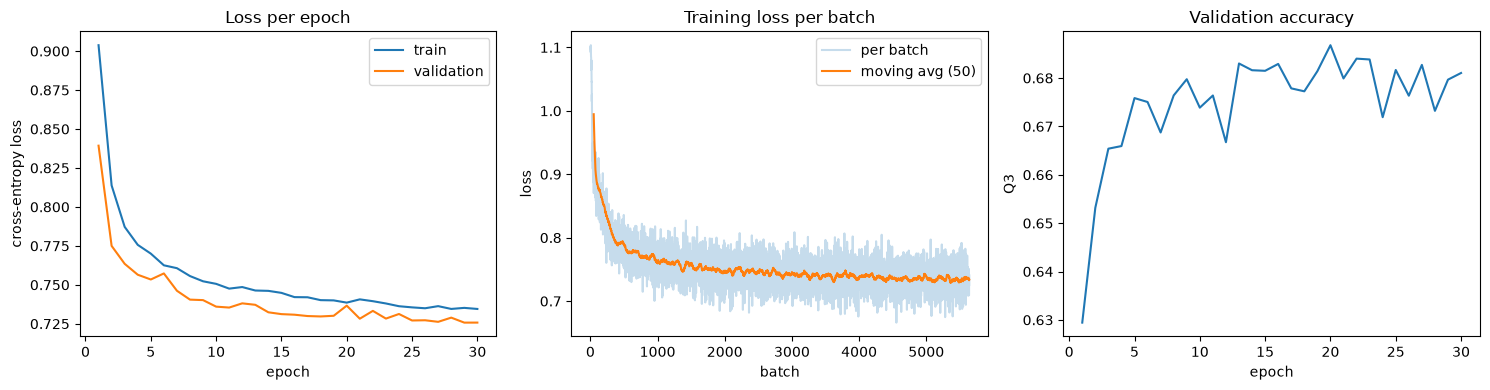

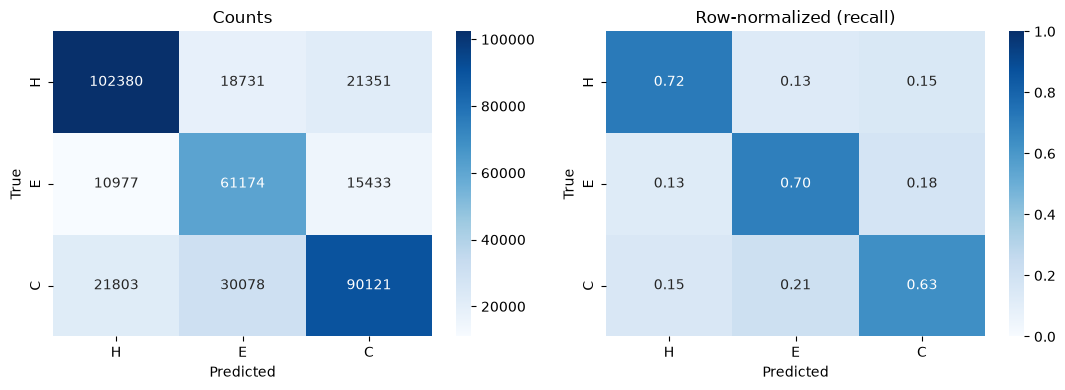

Q3 accuracy: 0.6818
class  precision    recall        f1   support
H          0.757     0.719     0.738    142462
E          0.556     0.698     0.619     87584
C          0.710     0.635     0.670    142002

Confusion matrix (rows = true, cols = predicted):
             H       E       C
H       102380   18731   21351
E        10977   61174   15433
C        21803   30078   90121


(0.6818340420722961,
 tensor([0.7575, 0.5562, 0.7101]),
 tensor([0.7186, 0.6985, 0.6346]))

In [7]:
from cnn_ss import *
from softmax_ss import plot_history, report

cnn_train = DataLoader(ChainDataset(train_df, encode_seq, encode_labels),
                       batch_size=32, shuffle=True, collate_fn=collate)
cnn_val   = DataLoader(ChainDataset(val_df, encode_seq, encode_labels),
                       batch_size=32, shuffle=False, collate_fn=collate)
cnn_test  = DataLoader(ChainDataset(test_df, encode_seq, encode_labels),
                       batch_size=32, shuffle=False, collate_fn=collate)

counts = torch.bincount(torch.cat([encode_labels(s) for s in train_df["structure"]])).float()
class_weight = counts.sum() / (len(counts) * counts)

cnn = CNN1D()
history = train_cnn(cnn, cnn_train, cnn_val, epochs=30, lr=1e-3, class_weight=class_weight)
plot_history(history)

_, pred, true = evaluate_cnn(cnn, cnn_test, nn.CrossEntropyLoss(ignore_index=PAD_LABEL))
report(pred, true)

## Use of ESM2 Encoder for Training

Previous models were encoded using one-hot encoding, which has seen descent success. However, there is a ceiling in the improvement in such a model as we do not have enough training data to properly represent the biochemical and structural properties of amino acids. By using a highly trained transformer with attention over the whole sequence, much of the work of the CNN is already done by the encoder, so the CNN can learn more complex behavior that it would not be able to otherwise.

In [12]:
import re
import torch
from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoTokenizer, EsmModel

checkpoint = "facebook/esm2_t6_8M_UR50D"
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

tokenizer = AutoTokenizer.from_pretrained(checkpoint)
esm = EsmModel.from_pretrained(checkpoint, add_pooling_layer=False).eval().to(device)
EMB_DIM = esm.config.hidden_size        # 320 for this checkpoint

def clean(seq):
    # anything that isn't one of the 20 standard residues becomes X
    return re.sub(r"[^ACDEFGHIKLMNPQRSTVWY]", "X", seq.upper())

@torch.no_grad()
def embed_sequences(seqs, batch_size=16):
    """Return a list of (L, EMB_DIM) tensors, one per sequence, in the original order."""
    seqs = [clean(s) for s in seqs]
    order = sorted(range(len(seqs)), key=lambda i: len(seqs[i]))   # similar lengths -> less padding
    out = [None] * len(seqs)
    for start in range(0, len(order), batch_size):
        idx = order[start:start + batch_size]
        enc = tokenizer([seqs[i] for i in idx], return_tensors="pt", padding=True).to(device)
        hidden = esm(**enc).last_hidden_state                      # (B, L_max + 2, EMB_DIM)
        for row, i in enumerate(idx):
            out[i] = hidden[row, 1:len(seqs[i]) + 1].cpu()         # drop <cls> and <eos>
    return out

ss_to_idx = {"H": 0, "E": 1, "C": 2}
def encode_labels(s):
    return torch.tensor([ss_to_idx[c] for c in s], dtype=torch.long)

def build(split_df, cache_path=None):
    if cache_path and os.path.exists(cache_path):
        X, y = torch.load(cache_path)
    else:
        X = torch.cat(embed_sequences(split_df["sequence"].tolist()))
        y = torch.cat([encode_labels(s) for s in split_df["structure"]])
        if cache_path:
            torch.save((X, y), cache_path)
    return TensorDataset(X, y)

import os
train_dataset = build(train_df, "esm_train.pt")
val_dataset   = build(val_df,   "esm_val.pt")
test_dataset  = build(test_df,  "esm_test.pt")

train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=256, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=256, shuffle=False)
print(len(train_dataset), len(val_dataset), len(test_dataset))

Loading weights: 100%|██████████| 102/102 [00:00<00:00, 9915.61it/s]
[transformers] EsmModel LOAD REPORT from: facebook/esm2_t6_8M_UR50D
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


1305365 186500 372048


epoch   1 | train loss 0.6123 | val loss 0.5967 | val Q3 0.7501
epoch   2 | train loss 0.5995 | val loss 0.5966 | val Q3 0.7502
epoch   3 | train loss 0.5993 | val loss 0.5970 | val Q3 0.7506
epoch   4 | train loss 0.5993 | val loss 0.5967 | val Q3 0.7524
epoch   5 | train loss 0.5993 | val loss 0.5969 | val Q3 0.7507
epoch   6 | train loss 0.5993 | val loss 0.5966 | val Q3 0.7492
early stopping at epoch 6


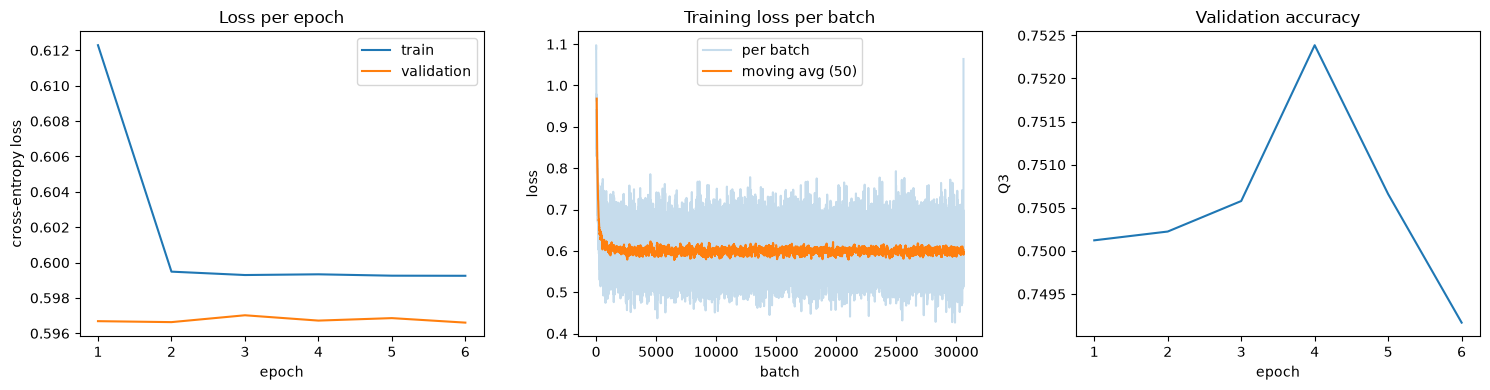

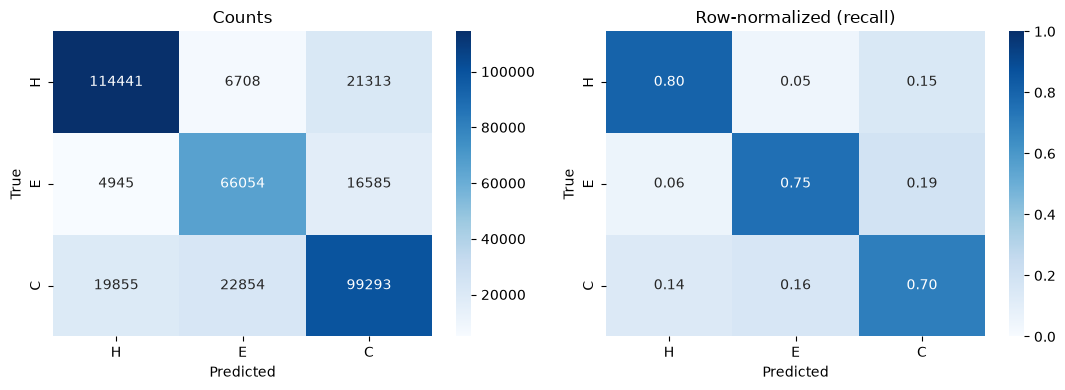

Q3 accuracy: 0.7520
class  precision    recall        f1   support
H          0.822     0.803     0.812    142462
E          0.691     0.754     0.721     87584
C          0.724     0.699     0.711    142002

Confusion matrix (rows = true, cols = predicted):
             H       E       C
H       114441    6708   21313
E         4945   66054   16585
C        19855   22854   99293


(0.7520212531089783,
 tensor([0.8219, 0.6908, 0.7238]),
 tensor([0.8033, 0.7542, 0.6992]))

In [13]:
model = SoftmaxRegression(n_features=EMB_DIM)
history = train(model, train_loader, val_loader, epochs=20, lr=1e-3, class_weight=class_weight)

plot_history(history)

_, pred, true = evaluate(model, test_loader, nn.CrossEntropyLoss())
report(pred, true)

In [ ]:
import os
from cnn_ss import ChainDataset, collate, CNN1D, train_cnn, evaluate_cnn, PAD_LABEL
from softmax_ss import plot_history, report

if os.path.exists("esm_chains.pt"):
    emb_cache = torch.load("esm_chains.pt")
else:
    emb_cache = {}

all_seqs = pd.concat([train_df, val_df, test_df])["sequence"].unique()
missing = [s for s in all_seqs if s not in emb_cache]
print(f"embedding {len(missing)} new sequences")

if missing:
    emb_cache.update(zip(missing, embed_sequences(missing)))
    torch.save(emb_cache, "esm_chains.pt")

get_emb = lambda s: emb_cache[s]

embedding 7726 new sequences


epoch   1 | train loss 0.5982 | val loss 0.5492 | val Q3 0.7719
epoch   2 | train loss 0.5489 | val loss 0.5386 | val Q3 0.7765
epoch   3 | train loss 0.5353 | val loss 0.5336 | val Q3 0.7681
epoch   4 | train loss 0.5283 | val loss 0.5333 | val Q3 0.7764
epoch   5 | train loss 0.5211 | val loss 0.5288 | val Q3 0.7735
epoch   6 | train loss 0.5155 | val loss 0.5265 | val Q3 0.7772
epoch   7 | train loss 0.5111 | val loss 0.5263 | val Q3 0.7773
epoch   8 | train loss 0.5065 | val loss 0.5232 | val Q3 0.7780
epoch   9 | train loss 0.5020 | val loss 0.5239 | val Q3 0.7792
epoch  10 | train loss 0.4986 | val loss 0.5254 | val Q3 0.7774
epoch  11 | train loss 0.4961 | val loss 0.5256 | val Q3 0.7809
epoch  12 | train loss 0.4905 | val loss 0.5269 | val Q3 0.7758
epoch  13 | train loss 0.4879 | val loss 0.5317 | val Q3 0.7692
early stopping at epoch 13


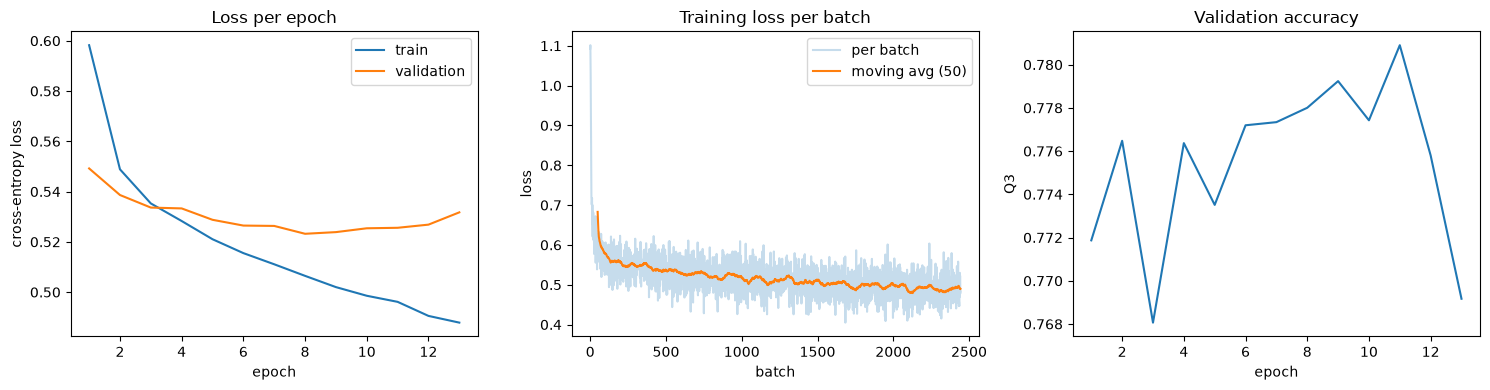

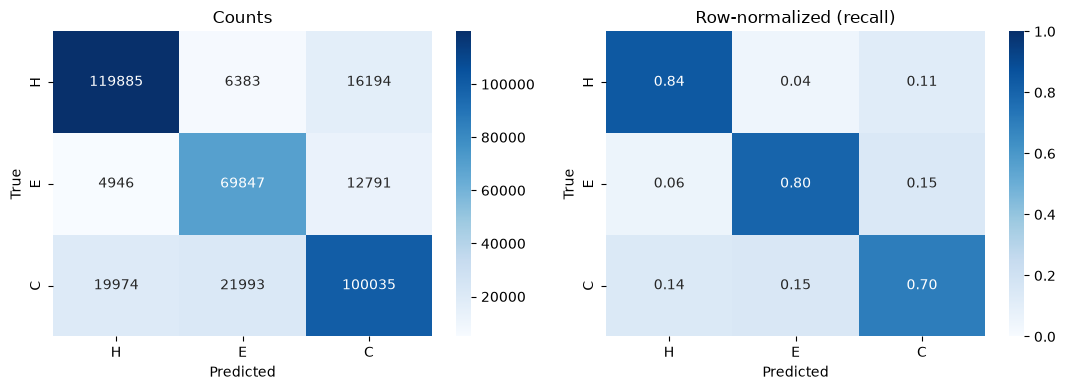

Q3 accuracy: 0.7788
class  precision    recall        f1   support
H          0.828     0.842     0.835    142462
E          0.711     0.797     0.752     87584
C          0.775     0.704     0.738    142002

Confusion matrix (rows = true, cols = predicted):
             H       E       C
H       119885    6383   16194
E         4946   69847   12791
C        19974   21993  100035


(0.7788430452346802,
 tensor([0.8279, 0.7111, 0.7753]),
 tensor([0.8415, 0.7975, 0.7045]))

In [24]:
def make_loader(split_df, shuffle):
    return DataLoader(ChainDataset(split_df, get_emb, encode_labels),
                      batch_size=32, shuffle=shuffle, collate_fn=collate)

cnn_train, cnn_val, cnn_test = make_loader(train_df, True), make_loader(val_df, False), make_loader(test_df, False)

counts = torch.bincount(torch.cat([encode_labels(s) for s in train_df["structure"]])).float()
class_weight = counts.sum() / (len(counts) * counts)

cnn = CNN1D(n_in=EMB_DIM, hidden=128)
history = train_cnn(cnn, cnn_train, cnn_val, epochs=30, lr=1e-3, class_weight=class_weight,
                    device=device)
plot_history(history)

_, pred, true = evaluate_cnn(cnn, cnn_test, nn.CrossEntropyLoss(ignore_index=PAD_LABEL), device=device)
report(pred, true)

In [25]:
torch.save(cnn.state_dict(), "cnn_esm.pt")

## Visualization of Final Model

ExecutableNotFound: failed to execute PosixPath('dot'), make sure the Graphviz executables are on your systems' PATH